# 01 Preparación y exploración semanal de dengue en Cali

**Propósito:** obtener una serie semanal trazable antes de entrenar. Este piloto utiliza notificaciones del evento 210 con estados 2, 3 y 5; sus conteos no equivalen a todas las infecciones existentes. La comparación de municipios y el clima quedan para etapas siguientes.

Ejecutar las celdas en orden. Los cálculos están en `src/dengue/pipeline.py` para reutilizarlos y probarlos. No se muestran filas individuales de pacientes. Los originales permanecen intactos.

**Etapas:** extracción → auditoría → calendario → exploración → canal → variables causales → exportación. El notebook 02 realiza el primer entrenamiento después de estas comprobaciones.

## 1 Configuración y fuentes

La extracción se ejecuta antes de este notebook con `python scripts/extraer_cali.py`. Lee los 19 Excel, conserva archivo y fila de origen y genera una huella de las 69 columnas originales por registro. Los CSV derivados del compañero sirven como contraste; no constituyen la fuente canónica porque su calendario necesita reconstrucción.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/piloto.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from dengue.pipeline import *
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (12,4), 'font.size': 10})
FIG = ROOT / 'reports/figures'
FIG.mkdir(parents=True, exist_ok=True)
cfg = config()
display(pd.Series(cfg, name='Configuración acordada').to_frame())

,Configuración acordada
municipio,76001
nombre_municipio,Cali
anio_inicial,2007
anio_final,2025
ventana_canal_anios,5
cuantil_canal,0.75
min_anios_canal,5
fin_entrenamiento,2021
fin_validacion,2023
anio_prueba,2024


In [2]:
source = ROOT / 'data/raw/cali_original.csv'
if not source.exists():
    raise FileNotFoundError('Ejecutar primero scripts/extraer_cali.py')
raw = pd.read_csv(source, dtype='string', keep_default_na=False)
manifest = pd.DataFrame(json.loads((ROOT/'data/raw/manifiesto_fuentes.json').read_text(encoding='utf-8')))
display(manifest[['archivo','filas','filas_cali','sha256']])
print(f'Extraídos: {len(raw):,} registros; columnas: {raw.shape[1]}')
assert len(raw) == manifest.filas_cali.sum()

,archivo,filas,filas_cali,sha256
0,Datos_2007_210.xlsx,35074,137,9a6e8847af35cd1be5ec494562c790830f058e49c1b783...
1,Datos_2008_210.xlsx,32793,1028,e550c7ff0467a79d2ccc530d9fe3a320242b35ddee3dd4...
2,Datos_2009_210.xlsx,45345,5680,3464d6d9639bb9eef353eb184a32b2f432442c66ef2fde...
3,Datos_2010_210.xlsx,147224,11002,ad60638306d230926a1656081b83fbb02f598c97fce101...
4,Datos_2011_210.xlsx,29386,1395,bd2843e0bfe30680e23788fa62dd0a882cf2c7b8fbf942...
5,Datos_2012_210.xlsx,52467,1967,353733f6b8cc91ef62b6fa3c7e459ca40be7e4b38151a0...
6,Datos_2013_210.xlsx,122441,17013,df4f72a1f100cdecde69b1d2ee51c8ac6c29b48a21d6be...
7,Datos_2014_210.xlsx,105356,5877,1078cf4fa93beaccdb683e5e3cb1a45788fbf349d92491...
8,Datos_2015_210.xlsx,95023,14438,2c0c52525f53a8c4b6d1e6ed868e2164feef7bdc453b4b...
9,Datos_2016_210.xlsx,100117,19310,08a534ef90c7eea144711713431befee23087ce63d91b3...


Extraídos: 160,709 registros; columnas: 24


## 2 Reglas de limpieza y trazabilidad

1. Eliminar solo duplicados exactos de las columnas originales, conservando el primer origen; no deduplicar por identificador aislado.
2. Conservar evento 210, país 170, departamento 76, municipio 001 y estados finales 2/3/5.
3. Parsear día/mes/año explícitamente, ISO o serial Excel; nunca inferir fechas ambiguas.
4. Usar exclusivamente inicio de síntomas; si falta o no puede parsearse, separar el registro sin sustituirlo por notificación.
5. Conservar los registros con notificación anterior a síntomas y marcar la anomalía; no utilizar FEC_NOT como requisito de inclusión. Comprobar síntomas frente a consulta como control adicional, sin inventar fechas.
6. Conservar retrasos mayores de 180 días como diagnóstico, sin recortarlos artificialmente.
7. Limitar por año epidemiológico validado, no por nombre de archivo.

El estado final y las revisiones posteriores impiden reconstruir perfectamente qué se sabía en cada corte. La evaluación inicial será retrospectiva.

**Decisión actualizada v1:** las 7.069 cronologías negativas de notificación se concentran en el archivo original de 2013. Se conservan como registros con síntomas válidos, con bandera de anomalía. El inicio de síntomas es interpretable en 160.704 de 160.709 registros, y no hay síntomas posteriores a consulta cuando ambas fechas están disponibles. Esto respalda su elección, sin garantizar que cada fecha sea verdadera. Los cinco registros sin inicio se separan. La versión anterior y sus métricas se guardaron en `data/historico/cronologia_v0/`.

In [3]:
micro, auditoria, calidad = preparar_microdatos(raw, cfg)
display(auditoria)
display(pd.Series({k:v for k,v in calidad.items() if k!='diagnostico_por_archivo'}, name='Diagnóstico').to_frame())
display(pd.DataFrame(calidad['diagnostico_por_archivo']))
display(micro.groupby('Estado_final_de_caso').size().rename('registros').to_frame())
assert micro.HUELLA_REGISTRO.is_unique
assert micro.cod_municipio.eq('76001').all()

,etapa,filas_restantes,excluidos
0,extraidos_cali,160709,0
1,sin_duplicados_exactos_originales,160709,0
2,evento_y_ubicacion_validos,160709,0
3,estados_2_3_5,160709,0
4,inicio_sintomas_valido_sin_sustitucion,160704,5
5,dentro_ventana_epidemiologica,160703,1


,Diagnóstico
ini_sin_no_parseable,5
fec_not_no_parseable,0
sintomas_posteriores_notificacion,7069
retrasos_mayores_180,2503
consecutive_repetidos_no_eliminados_por_id,42
fecha_principal,INI_SIN
porcentaje_inicio_valido,99.996889
fec_con_no_parseable,6
sintomas_posteriores_consulta,0
filas_finales,160703


,ARCHIVO_ORIGEN,registros,cronologias_negativas,mayores_180,sin_inicio,pct_cronologia_negativa
0,Datos_2007_210.xlsx,137,0,2,0,0.000000
1,Datos_2008_210.xlsx,1028,0,7,0,0.000000
2,Datos_2009_210.xlsx,5680,0,2,0,0.000000
3,Datos_2010_210.xlsx,11002,0,2,0,0.000000
4,Datos_2011_210.xlsx,1395,0,4,0,0.000000
5,Datos_2012_210.xlsx,1967,0,13,0,0.000000
6,Datos_2013_210.xlsx,17013,7069,2018,3,41.550579
7,Datos_2014_210.xlsx,5877,0,24,0,0.000000
8,Datos_2015_210.xlsx,14438,0,142,0,0.000000
9,Datos_2016_210.xlsx,19310,0,34,2,0.000000


,registros
Estado_final_de_caso,
2,66796
3,81203
5,12704


## 3 Reconstrucción del calendario epidemiológico

Se usan semanas domingo–sábado. La primera semana contiene al menos cuatro días del año (se obtiene desde el 4 de enero). Verificación de referencia INS 2025: semana 1 del 29/12/2024 al 04/01/2025 y semana 53 del 28/12/2025 al 03/01/2026. Debe contrastarse el calendario histórico si se incorporan otras convenciones o fuentes.

No se fuerza un panel de 52 semanas por año. Una semana sin registros se conserva con `n_registros=0` como hecho de extracción, pero `casos=NaN`: todavía no certificamos cero casos epidemiológicos ni completitud del reporte.

In [4]:
panel = construir_panel(micro, cfg)
display(panel.groupby('anio_epi').agg(semanas=('semana_epi','size'),
    notificaciones=('n_registros','sum'), semanas_sin_registros=('semana_con_registros',lambda x: (~x).sum())))
display(panel.loc[panel.semana_epi.eq(53), ['anio_epi','semana_epi','inicio_semana','fin_semana','n_registros']])
print('Reconciliación:', panel.n_registros.sum(), 'registros =', len(micro), 'microdatos incluidos')
assert panel.n_registros.sum() == len(micro)

,semanas,notificaciones,semanas_sin_registros
anio_epi,,,
2007,52,138,19
2008,53,1027,0
2009,52,5682,0
2010,52,11000,0
2011,52,1394,0
2012,52,1967,0
2013,52,17013,0
2014,53,5874,0
2015,52,14439,0


,anio_epi,semana_epi,inicio_semana,fin_semana,n_registros
104,2008,53,2008-12-28,2009-01-03,3
417,2014,53,2014-12-28,2015-01-03,177
730,2020,53,2020-12-27,2021-01-02,112
991,2025,53,2025-12-28,2026-01-03,30


Reconciliación: 160703 registros = 160703 microdatos incluidos


## 4 Contraste con la serie recibida

Las diferencias combinan la corrección de calendario y las exclusiones explícitas. No deben atribuirse todas a semanas 53. La comparación no altera el archivo del compañero. Los porcentajes clínicos contemporáneos y los valores interpolados del CSV anterior no entran a la matriz inicial.

In [5]:
workspace = next((p for p in ROOT.parents if (p/'06_serie_temporal_semanal_76001_lista_ML.csv').exists()), None)
if workspace:
    anterior = pd.read_csv(workspace/'06_serie_temporal_semanal_76001_lista_ML.csv')
    display(pd.DataFrame({'serie':['Recibida','Reconstruida'],
        'filas':[len(anterior), len(panel)],
        'suma_notificaciones':[int(anterior.casos_totales_validos.sum()), int(panel.n_registros.sum())]}))
    # Comprobación independiente de la incompatibilidad de claves/fechas recibidas.
    amigo = pd.read_csv(workspace/'05_microdatos_limpios_municipio_76001.csv', usecols=['ANIO_EPI','SEMANA_EPI','FECHA_EPIDEMIOLOGICA'])
    amigo['fecha'] = pd.to_datetime(amigo.FECHA_EPIDEMIOLOGICA, format='%Y-%m-%d', errors='coerce')
    limites = amigo.groupby(['ANIO_EPI','SEMANA_EPI']).fecha.agg(['min','max'])
    print('Grupos recibidos con fechas que abarcan más de 7 días:', int(((limites['max']-limites['min']).dt.days>6).sum()))
else:
    print('Contraste opcional omitido: CSV del compañero no localizado.')

,serie,filas,suma_notificaciones
0,Recibida,988,160379
1,Reconstruida,992,160703


Grupos recibidos con fechas que abarcan más de 7 días: 217


## 5 Evolución histórica y cobertura

Una caída de notificaciones no demuestra por sí misma disminución de transmisión: puede combinar vigilancia, clasificación y cambios de reporte. Las cifras de 2025 deben revisarse en ese contexto. La vista histórica es descriptiva; no se utiliza para escoger variables o parámetros con el conjunto de prueba.

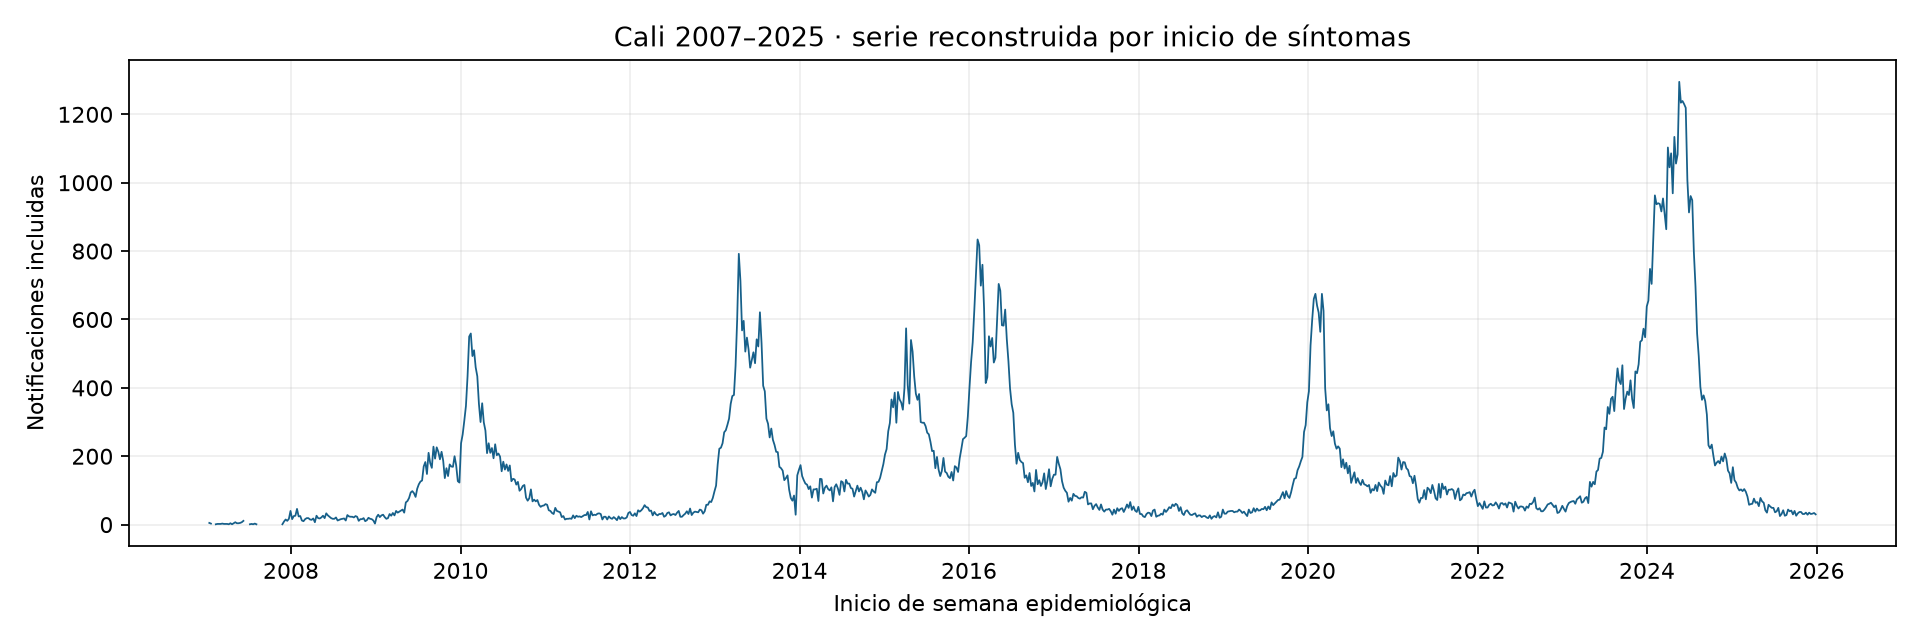

In [6]:
fig, ax = plt.subplots()
ax.plot(panel.inicio_semana, panel.casos, linewidth=0.8, color='#17608a')
ax.set(xlabel='Inicio de semana epidemiológica', ylabel='Notificaciones incluidas', title='Cali 2007–2025 · serie reconstruida por inicio de síntomas')
ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(FIG/'01_serie_semanal.png', dpi=160); plt.close(fig)
display(Image(filename=str(FIG/'01_serie_semanal.png')))

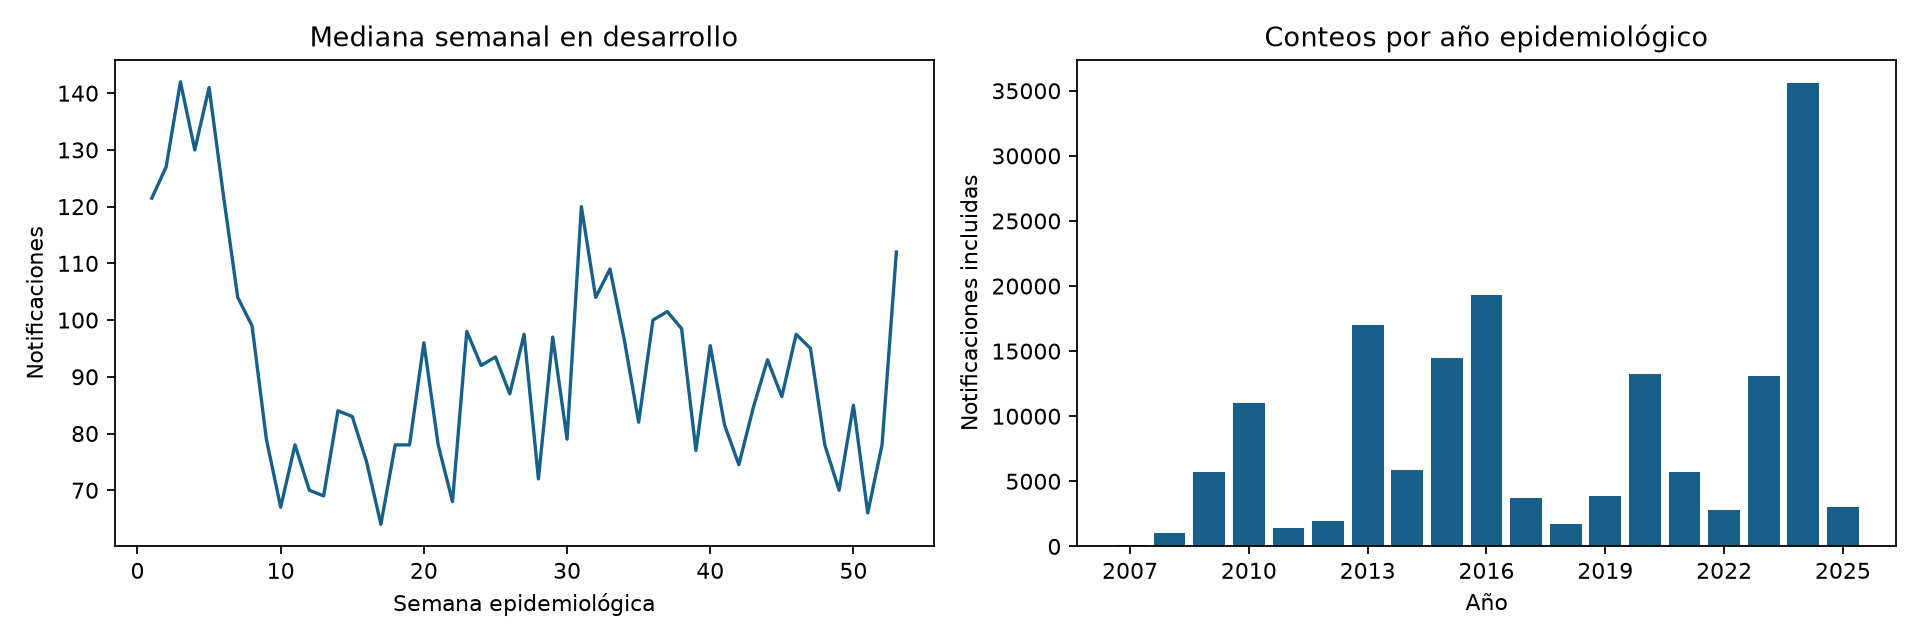

In [7]:
# Solo desarrollo para explorar estacionalidad sin seleccionar usando prueba.
desarrollo = panel.loc[panel.anio_epi<=cfg['fin_entrenamiento']]
estacional = desarrollo.groupby('semana_epi').casos.agg(['median','count'])
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(estacional.index,estacional['median'],color='#17608a')
axes[0].set(title='Mediana semanal en desarrollo',xlabel='Semana epidemiológica',ylabel='Notificaciones')
anual = panel.groupby('anio_epi').n_registros.sum()
axes[1].bar(anual.index,anual.values,color='#17608a')
axes[1].set(title='Conteos por año epidemiológico',xlabel='Año',ylabel='Notificaciones incluidas')
axes[1].set_xticks(list(range(2007,2026,3)))
fig.tight_layout();fig.savefig(FIG/'02_estacionalidad_anual.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'02_estacionalidad_anual.png')))

## 6 Retrasos y disponibilidad

Los retrasos se calculan sin convertir negativos en cero ni valores altos en 180. Las cronologías negativas de notificación se conservan como anomalías; solo los retrasos no negativos se utilizan para resumir demoras interpretables. La notificación no decide la agrupación ni la inclusión. Los conteos finales por síntomas pueden incluir notificaciones recibidas después del corte nominal: esto limita la interpretación operacional del modelo de la siguiente etapa.

,retraso_notificacion_dias
count,153634.000000
mean,14.306722
std,37.573284
min,0.000000
50%,5.000000
90%,19.000000
95%,73.000000
99%,215.000000
max,430.000000


Anomalías de notificación conservadas: 7069
Porcentaje con notificación más de 7 días después de síntomas: 26.39 (entre retrasos no negativos disponibles)


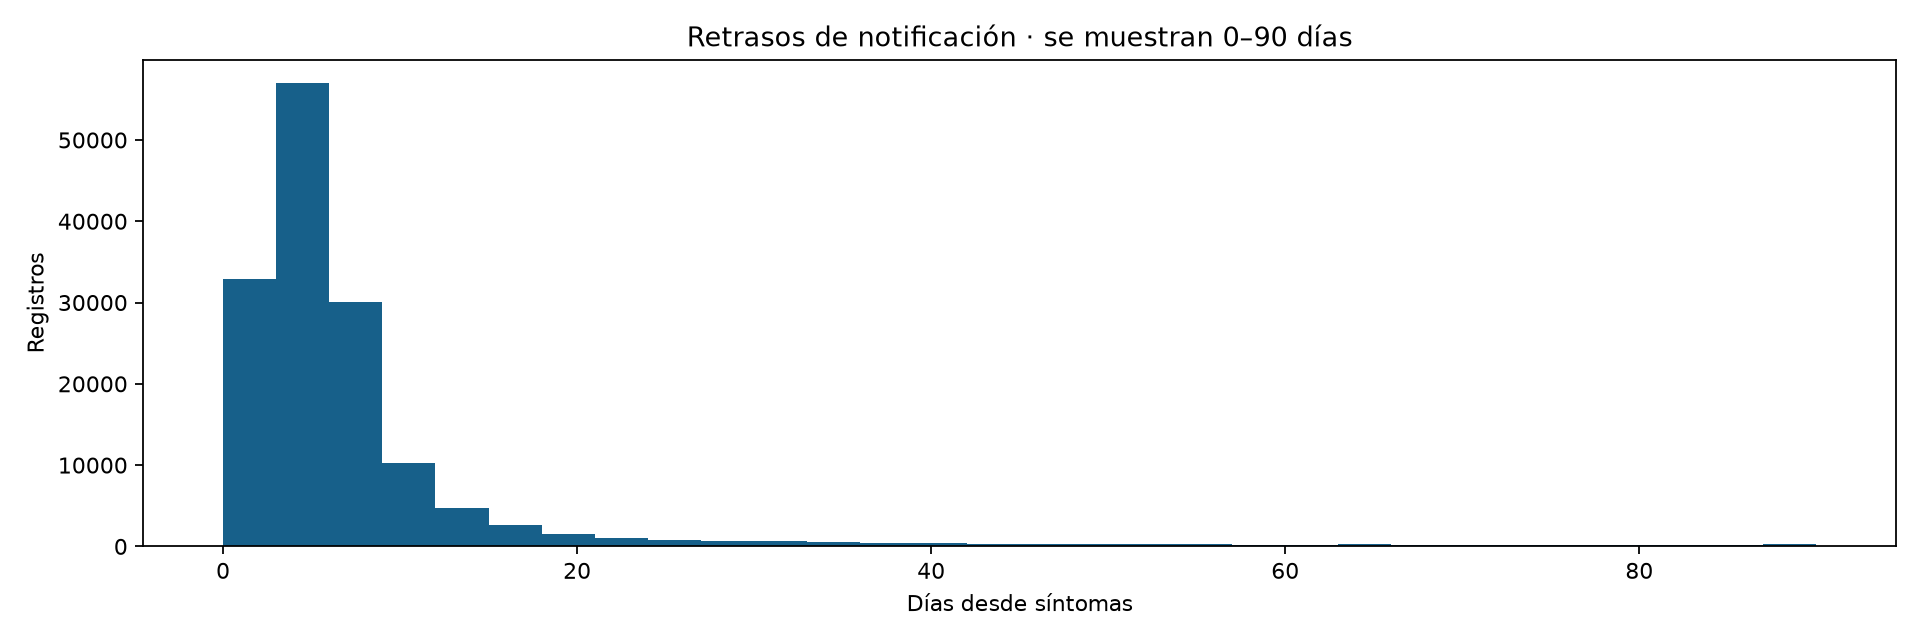

In [8]:
demora_valida = micro.retraso_notificacion_dias.where(micro.retraso_notificacion_dias.ge(0))
display(demora_valida.describe(percentiles=[.5,.9,.95,.99]).to_frame())
print('Anomalías de notificación conservadas:', int(micro.flag_notificacion_anterior_sintomas.sum()))
print('Porcentaje con notificación más de 7 días después de síntomas:',
      round(100*demora_valida.dropna().gt(7).mean(),2), '(entre retrasos no negativos disponibles)')
fig,ax=plt.subplots()
delay = demora_valida.dropna()
ax.hist(delay[delay<=90],bins=30,color='#17608a')
ax.set(title='Retrasos de notificación · se muestran 0–90 días',xlabel='Días desde síntomas',ylabel='Registros')
fig.tight_layout();fig.savefig(FIG/'03_retrasos.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'03_retrasos.png')))

## 7 Definición inicial del exceso

Para el objetivo semanal t, el umbral es el percentil 75 de los conteos de **esa misma semana epidemiológica en los cinco años anteriores**, con interpolación lineal del cuantil. Se requieren cinco valores válidos; si faltan, no se asigna etiqueta. `exceso=1` cuando el conteo observado supera estrictamente el umbral.

Es una definición operacional inicial, no una declaración oficial de epidemia ni una reproducción del canal geométrico de Bortman. Cinco observaciones por semana producen umbrales inestables; queda pendiente el análisis de sensibilidad. Las semanas 53 se conservan en la serie y en los rezagos, aunque pueden no tener suficientes años previos para etiquetarse. Los años iniciales sirven para inicializar el canal.

In [9]:
panel = agregar_canal(panel,cfg)
display(panel.groupby('anio_epi').agg(etiquetadas=('exceso','count'),positivas=('exceso','sum')))
display(panel.loc[panel.exceso.notna(), ['anio_epi','semana_epi','casos','n_anios_canal','umbral_casos','exceso']].head(10))
assert panel.loc[panel.exceso.notna(),'n_anios_canal'].ge(5).all()

,etiquetadas,positivas
anio_epi,,
2007,0,0.0
2008,0,0.0
2009,0,0.0
2010,0,0.0
2011,0,0.0
2012,33,9.0
2013,52,51.0
2014,52,7.0
2015,52,51.0


,anio_epi,semana_epi,casos,n_anios_canal,umbral_casos,exceso
263,2012,3,26.0,5,42.0,0.0
264,2012,4,33.0,5,40.0,0.0
267,2012,7,38.0,5,49.0,0.0
268,2012,8,42.0,5,40.0,1.0
269,2012,9,48.0,5,38.0,1.0
270,2012,10,57.0,5,36.0,1.0
271,2012,11,51.0,5,34.0,1.0
272,2012,12,50.0,5,27.0,1.0
273,2012,13,40.0,5,40.0,0.0
274,2012,14,41.0,5,35.0,1.0


## 8 Variables disponibles antes de la semana objetivo

La fila t corresponde a la semana a predecir; su corte nominal es el sábado inmediatamente anterior. Se usan conteos de t−1, t−2, t−3, t−4, t−8 y t−12, media/desviación de las cuatro semanas anteriores y estacionalidad conocida del objetivo. Se exige historia completa para estas variables; no se interpolan faltantes.

Se excluyen como predictores los conteos del objetivo, su etiqueta, su umbral y las características de pacientes de esa semana. El umbral se guarda para interpretar la etiqueta y construir la referencia de persistencia. Incluso los rezagos finales deben interpretarse como evaluación retrospectiva, pues el retraso de notificación impide afirmar que estuvieran completos al corte.

In [10]:
panel = agregar_features(panel)
display(panel.loc[panel.elegible_modelo,['inicio_semana','corte_prediccion',*FEATURES,'exceso']].head())
display(pd.DataFrame({'variable':FEATURES,'origen':['historia anterior']*8+['calendario conocido']*2}))
annual, summary = exportar_eda(raw,micro,auditoria,calidad,panel)
display(annual)
display(pd.Series({k:v for k,v in summary.items() if k!='diagnostico_por_archivo'},name='Resultado de preparación').to_frame())

,inicio_semana,corte_prediccion,lag_1,lag_2,lag_3,lag_4,lag_8,lag_12,media_4,std_4,semana_sin,semana_cos,exceso
263,2012-01-15,2012-01-14,28.0,37.0,34.0,21.0,16.0,22.0,30.00,7.071068,0.239316,0.970942,0.0
264,2012-01-22,2012-01-21,26.0,28.0,37.0,34.0,22.0,18.0,31.25,5.123475,0.354605,0.935016,0.0
267,2012-02-12,2012-02-11,42.0,25.0,33.0,26.0,21.0,16.0,31.50,7.852813,0.663123,0.748511,0.0
268,2012-02-19,2012-02-18,38.0,42.0,25.0,33.0,34.0,22.0,34.50,7.325754,0.748511,0.663123,1.0
269,2012-02-26,2012-02-25,42.0,38.0,42.0,25.0,37.0,18.0,36.75,8.057088,0.822984,0.568065,1.0


,variable,origen
0,lag_1,historia anterior
1,lag_2,historia anterior
2,lag_3,historia anterior
3,lag_4,historia anterior
4,lag_8,historia anterior
5,lag_12,historia anterior
6,media_4,historia anterior
7,std_4,historia anterior
8,semana_sin,calendario conocido
9,semana_cos,calendario conocido


,semanas,con_registros,notificaciones_incluidas,elegibles
anio_epi,,,,
2007,52,33,138,0
2008,53,53,1027,0
2009,52,52,5682,0
2010,52,52,11000,0
2011,52,52,1394,0
2012,52,52,1967,33
2013,52,52,17013,52
2014,53,53,5874,52
2015,52,52,14439,52


,Resultado de preparación
ini_sin_no_parseable,5
fec_not_no_parseable,0
sintomas_posteriores_notificacion,7069
retrasos_mayores_180,2503
consecutive_repetidos_no_eliminados_por_id,42
fecha_principal,INI_SIN
porcentaje_inicio_valido,99.996889
fec_con_no_parseable,6
sintomas_posteriores_consulta,0
filas_finales,160703


## 9 Cierre de la fase exploratoria y siguiente paso

Se exportaron auditoría, manifiesto de fuentes, microdatos locales, panel completo y figuras. La suma se reconcilia después de exclusiones explícitas. Se conservan semanas sin registros como desconocidas y la semana 53 sin eliminaciones artificiales.

**Siguiente notebook:** regresión logística regularizada, entrenamiento hasta 2021, validación 2022–2023, prueba 2024 y evaluación adicional 2025. No se ajusta el modelo con las métricas de prueba. Pendientes: revisión del caso/fecha con el experto, cobertura externa, sensibilidad del canal, simulación con disponibilidad real, clima y extensión a otros municipios.

Referencias: [calendario INS 2025](https://portalsivigila.ins.gov.co/Documentos%20compartidos/Calendario%202025.pdf) y [Umaña et al. 2026](https://publichealth.jmir.org/2026/1/e79914).